# U-Net multi-variables (same-grid, early fusion) — Perfect Prognosis, Madagascar

Identique à `qm_ablation`, mais **le nombre de prédicteurs est auto-détecté** dans le NetCDF
(3, 6, ... variables). `model.py` s'adapte tout seul au nombre de canaux.

- **Entrée** : `*_aladin_up` (toutes les variables) **+ orog** (early fusion)
- **Cible**  : `tas_aladin`
- **Splits** : train ≤2006, val 2007-2010, test ≥2011.

> Exécution **locale VSCode**. Choisis le kernel de ton venv (`tensorflow`, `xarray`, `netCDF4`, ...).


## 0. Imports & configuration

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import tensorflow as tf

# --- Localisation du code (model.py / dataset.py) ---
if Path('model.py').exists():
    HERE = Path('.').resolve()
elif Path('qm_ablation_multivar/model.py').exists():
    HERE = Path('qm_ablation_multivar').resolve()
else:
    raise FileNotFoundError("model.py introuvable : ouvre le notebook dans le repo ou dans qm_ablation_multivar/.")
sys.path.insert(0, str(HERE))
from model   import build_unet, mse, RMSE, MAE
from dataset import load_grid_dates, make_splits, build_X, build_Y, detect_vars

ROOT = HERE.parent

# --- Dossier des données : on prend le candidat qui contient le PLUS de variables (multi-var) ---
def _find_proc(root):
    best, best_n = None, -1
    for c in ['datasets_v2', 'processed_v2', 'datasets']:
        d = root / c
        ncs = sorted(d.glob('training_dataset*norm.nc')) if d.exists() else []
        if ncs:
            n = sum(1 for v in xr.open_dataset(ncs[0]).data_vars if str(v).endswith('_aladin'))
            if n > best_n:
                best, best_n = d, n
    return best
PROC = _find_proc(ROOT) or (ROOT / 'datasets_v2')   # ajuste ici si besoin

TRAIN_NC   = str(sorted(PROC.glob('training_dataset*norm.nc'))[-1])
_corr      = sorted(PROC.glob('gcm_*QMcorrected*norm.nc'))
CORR_NC    = str(_corr[-1]) if _corr else str(PROC / 'gcm_QMcorrected_absent.nc')   # pas requis ici
STATS_JSON = str(PROC / 'normalization_stats.json')

MODELS_DIR = ROOT / 'models' / 'qm_ablation_multivar'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

TARGET = 'tas'
VARS = tuple(v for v in detect_vars(TRAIN_NC) if v != TARGET)   # entrée = tout SAUF tas

BASE_CH    = 16
BATCH_SIZE = 16
LR         = 1e-4
MAX_EPOCHS = 75
PATIENCE   = 15

print('TF  :', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
print('Données        :', PROC)
print('TRAIN_NC       :', os.path.basename(TRAIN_NC))
print(f'Prédicteurs    : {VARS}  -> {len(VARS)+1} canaux d\'entrée (+ orog)')
for p in [TRAIN_NC, STATS_JSON]:
    print(f"  {'OK ' if os.path.exists(p) else 'MANQUANT '} {os.path.basename(p)}")


TF  : 2.10.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Données        : C:\Users\admin\Documents\DocOwen\M2\LIGHTEN-IO\mada_downscaling\datasets_v2
TRAIN_NC       : training_dataset_madagascar_norm.nc
Prédicteurs    : ('tasmin', 'tasmax', 'hursmin', 'hursmax', 'rsds')  -> 6 canaux d'entrée (+ orog)
  OK  training_dataset_madagascar_norm.nc
  OK  normalization_stats.json


## 1. Grille, dates, splits

In [2]:
lat_hr, lon_hr, dates = load_grid_dates(TRAIN_NC)
NY, NX = lat_hr.shape
idx_train, idx_val, idx_test = make_splits(dates)
for name, idx in [('idx_train', idx_train), ('idx_val', idx_val), ('idx_test', idx_test)]:
    np.save(MODELS_DIR / (name + '.npy'), idx)
print(f"Grille {NY}x{NX} | train {len(idx_train)} / val {len(idx_val)} / test {len(idx_test)}")


Grille 136x81 | train 9496 / val 1461 / test 1461


## 2. Tableaux d'entraînement (entrée = toutes les variables `_aladin_up` + orog)

In [3]:
X_train = build_X(TRAIN_NC, CORR_NC, STATS_JSON, source='aladin_up', idx=idx_train, vars=VARS)
Y_train = build_Y(TRAIN_NC, idx_train, target='tas')
X_val   = build_X(TRAIN_NC, CORR_NC, STATS_JSON, source='aladin_up', idx=idx_val, vars=VARS)
Y_val   = build_Y(TRAIN_NC, idx_val, target='tas')
print(f"X_train {X_train.shape}  (C={X_train.shape[-1]})   Y_train {Y_train.shape}")
print(f"Canaux : {[f'{v}_aladin_up' for v in VARS] + ['orog']}")


X_train (9496, 136, 81, 6)  (C=6)   Y_train (9496, 136, 81, 1)
Canaux : ['tasmin_aladin_up', 'tasmax_aladin_up', 'hursmin_aladin_up', 'hursmax_aladin_up', 'rsds_aladin_up', 'orog']


## 3. Modèle (in_channels auto) + compilation (MSE)

In [4]:
tf.keras.backend.clear_session()
model = build_unet(in_channels=X_train.shape[-1], hr_h=NY, hr_w=NX, base_ch=BASE_CH)
model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss=mse, metrics=[RMSE(), MAE()])
model.summary(line_length=90)
print(f"\nin_channels = {X_train.shape[-1]}  |  paramètres = {model.count_params():,}")


Model: "unet_samegrid_earlyfusion_multivar"
__________________________________________________________________________________________
 Layer (type)                Output Shape        Param #    Connected to                  
 input (InputLayer)          [(None, 136, 81, 6  0          []                            
                             )]                                                           
                                                                                          
 conv2d (Conv2D)             (None, 136, 81, 16  864        ['input[0][0]']               
                             )                                                            
                                                                                          
 batch_normalization (BatchN  (None, 136, 81, 16  64        ['conv2d[0][0]']              
 ormalization)               )                                                            
                                              

## 4. Entraînement

In [5]:
ckpt = str(MODELS_DIR / 'best.weights.h5')
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(ckpt, monitor='val_loss', save_best_only=True,
                                       save_weights_only=True, verbose=0),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                     restore_best_weights=True, verbose=1),
]
history = model.fit(X_train, Y_train, validation_data=(X_val, Y_val),
                    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
np.save(MODELS_DIR / 'history.npy', history.history)
# trace des canaux utilisés (pour l'évaluation)
import json as _json
_json.dump({'vars': list(VARS), 'in_channels': int(X_train.shape[-1])},
           open(MODELS_DIR / 'channels.json', 'w'), indent=2)
best = int(np.argmin(history.history['val_loss'])) + 1
print(f"\nMeilleure époque {best} | val RMSE {history.history['val_rmse'][best-1]:.4f} | val MAE {history.history['val_mae'][best-1]:.4f}")
print("Poids :", ckpt)


Epoch 1/75
594/594 [==============================] - 27s 36ms/step - loss: 0.1192 - rmse: 0.3453 - mae: 0.2426 - val_loss: 0.0458 - val_rmse: 0.2140 - val_mae: 0.1610 - lr: 1.0000e-04
Epoch 2/75
594/594 [==============================] - 20s 34ms/step - loss: 0.0452 - rmse: 0.2125 - mae: 0.1621 - val_loss: 0.0321 - val_rmse: 0.1793 - val_mae: 0.1325 - lr: 1.0000e-04
Epoch 3/75
594/594 [==============================] - 20s 34ms/step - loss: 0.0357 - rmse: 0.1888 - mae: 0.1436 - val_loss: 0.0261 - val_rmse: 0.1615 - val_mae: 0.1198 - lr: 1.0000e-04
Epoch 4/75
594/594 [==============================] - 20s 33ms/step - loss: 0.0297 - rmse: 0.1724 - mae: 0.1305 - val_loss: 0.0212 - val_rmse: 0.1457 - val_mae: 0.1071 - lr: 1.0000e-04
Epoch 5/75
594/594 [==============================] - 20s 34ms/step - loss: 0.0261 - rmse: 0.1617 - mae: 0.1220 - val_loss: 0.0196 - val_rmse: 0.1402 - val_mae: 0.1042 - lr: 1.0000e-04
Epoch 6/75
594/594 [==============================] - 20s 33ms/step - loss:

## 5. Courbes d'apprentissage

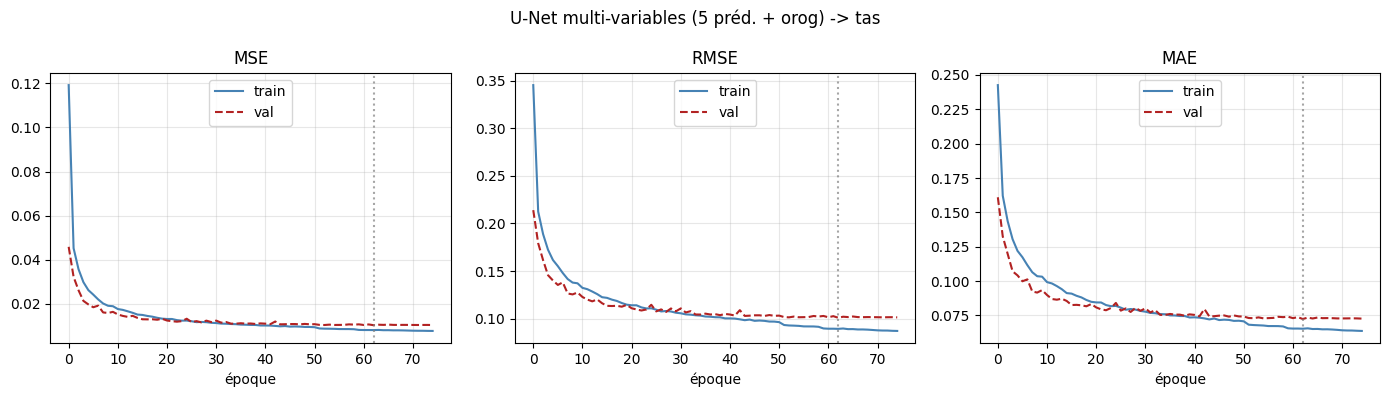

In [6]:
h = history.history
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle(f'U-Net multi-variables ({len(VARS)} préd. + orog) -> tas', fontsize=12)
for ax, (tr, va, lab) in zip(axes, [('loss','val_loss','MSE'), ('rmse','val_rmse','RMSE'), ('mae','val_mae','MAE')]):
    ax.plot(h[tr], label='train', color='steelblue')
    ax.plot(h[va], label='val', color='firebrick', linestyle='--')
    ax.axvline(best - 1, color='gray', linestyle=':', alpha=0.7)
    ax.set_title(lab); ax.set_xlabel('époque'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(MODELS_DIR / 'learning_curves.png', dpi=150); plt.show()
